<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/pinn_1_hidden_layer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1 Hidden Layer PINN to solve the pendulum equation for the first $5$ secs. Drop angle is $\pi/4=45^{\circ}$ from rest.


Starting training with SciPy L-BFGS-B optimizer...
This will take a few moments as it calculates numerical gradients for the weights...


/tmp/ipykernel_1881/2811317012.py:107: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


Training Complete! Final Loss: 0.000747


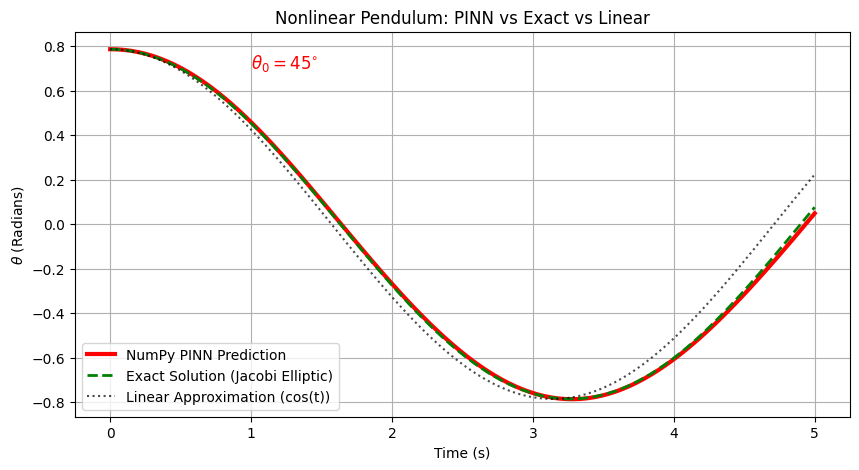

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp

class PureNumpyPINN:
    def __init__(self, n_hidden=32):
        self.H = n_hidden

        # 1. Initialize Weights and Biases (Glorot/Xavier style)
        # W1 connects Input (t) to Hidden layer
        self.W1 = np.random.randn(1, self.H) * np.sqrt(2.0 / (1 + self.H))
        self.b1 = np.zeros((1, self.H))

        # W2 connects Hidden layer to Output (theta)
        self.W2 = np.random.randn(self.H, 1) * np.sqrt(2.0 / (self.H + 1))
        self.b2 = np.zeros((1, 1))

    def pack_weights(self):
        """Flattens all weights and biases into a single 1D array for SciPy."""
        flat_list = [w.flatten() for w in self.W1]
        flat_list.extend([w.flatten() for w in self.W2])
        flat_list.extend([b.flatten() for b in self.b1])
        flat_list.extend([b.flatten() for b in self.b2])
        return np.concatenate(flat_list)

    def unpack_weights(self, params):
        """Reconstructs the weight matrices from the SciPy 1D array."""
        idx = 0
        self.W1 = params[idx : idx+self.H].reshape(1, self.H); idx += self.H
        self.b1 = params[idx : idx+self.H].reshape(1, self.H); idx += self.H
        self.W2 = params[idx : idx+self.H].reshape(self.H, 1); idx += self.H
        self.b2 = params[idx : idx+1].reshape(1, 1)

    def forward_with_physics(self, t):
        """
        Calculates the angle, velocity, and acceleration analytically
        using the manual chain rule.
        """
        # --- Stage 1: The Linear Step ---
        z = np.dot(t, self.W1) + self.b1

        # --- Stage 2: The Activation (tanh) ---
        a = np.tanh(z)

        # --- Stage 3: The Output (Angle) ---
        theta = np.dot(a, self.W2) + self.b2

        # --- Stage 4: First Derivative (Velocity) ---
        # Derivative of tanh(z) is (1 - tanh^2(z)) * dz/dt
        # dz/dt is simply W1
        da_dt = (1 - a**2) * self.W1
        velocity = np.dot(da_dt, self.W2)

        # --- Stage 5: Second Derivative (Acceleration) ---
        # Derivative of (1 - tanh^2(z)) * W1
        d2a_dt2 = -2 * a * (1 - a**2) * (self.W1**2)
        acceleration = np.dot(d2a_dt2, self.W2)

        return theta, velocity, acceleration

    def compute_loss(self, params, t_domain, t_ic, theta_0, omega_0):
        """Calculates the total error (Physics + Initial Conditions)."""
        # Load the current guesses for the weights
        self.unpack_weights(params)

        # 1. Physics Loss (The Differential Equation)
        theta, _, acceleration = self.forward_with_physics(t_domain)

        # Pendulum physics: theta'' + sin(theta) = 0
        residual = acceleration + np.sin(theta)
        loss_ode = np.mean(residual**2)

        # 2. Initial Condition Loss
        theta_pred_ic, velocity_pred_ic, _ = self.forward_with_physics(t_ic)

        loss_ic_position = np.mean((theta_pred_ic - theta_0)**2)
        loss_ic_velocity = np.mean((velocity_pred_ic - omega_0)**2)

        # Total Loss
        total_loss = loss_ode + loss_ic_position + loss_ic_velocity
        return total_loss

# ==========================================
# Training Setup
# ==========================================

# 1. Define the time domain and collocation points
# Simulating from t=0 to t=5 seconds with 100 points
t_domain = np.linspace(0, 5, 100).reshape(-1, 1)
#t_domain = np.linspace(0, 25, 500).reshape(-1, 1)
# 2. Define Initial Conditions
t_ic = np.array([[0.0]])     # t = 0
theta_0 = np.pi / 4          # Start at 45 degrees
omega_0 = 0.0                # Start from rest (0 velocity)

# 3. Initialize the NumPy PINN
pinn = PureNumpyPINN(n_hidden=32)
initial_weights = pinn.pack_weights()

print("Starting training with SciPy L-BFGS-B optimizer...")
print("This will take a few moments as it calculates numerical gradients for the weights...")

# 4. Train the network using SciPy
# We pass our loss function, initial weights, and the required data.
# jac='2-point' tells SciPy to figure out the weight backpropagation numerically.
res = minimize(
    fun=pinn.compute_loss,
    x0=initial_weights,
    args=(t_domain, t_ic, theta_0, omega_0),
    method='L-BFGS-B',
    jac='2-point',
    options={'maxiter': 5000, 'disp': True}
)

# Load the best weights found by the optimizer back into the model
pinn.unpack_weights(res.x)
print(f"Training Complete! Final Loss: {res.fun:.6f}")

# ==========================================
# Evaluation and Plotting
# ==========================================

# 1. Predict the motion using the trained PINN
theta_predicted, _, _ = pinn.forward_with_physics(t_domain)

# 2. Calculate the True Exact Solution (Jacobi Elliptic Functions)
k = np.sin(theta_0 / 2)
m = k**2

# ellipj returns (sn, cn, dn, ph).
sn, cn, dn, ph = sp.ellipj(t_domain.flatten(), m)

# To start at maximum amplitude (like a cosine wave), we must use
# the 'cd' function, which is defined as cn / dn
cd = cn / dn

exact_solution = 2 * np.arcsin(k * cd)

# 3. Calculate the Small-Angle Linear Approximation
linear_solution = theta_0 * np.cos(t_domain.flatten())

# Plot the comparisons
plt.figure(figsize=(10, 5))

# Plot PINN
plt.plot(t_domain, theta_predicted, 'r-', linewidth=3, label='NumPy PINN Prediction')

# Plot Exact Solution
plt.plot(t_domain, exact_solution, 'g--', linewidth=2, label='Exact Solution (Jacobi Elliptic)')

# Plot Linear Approximation
plt.plot(t_domain, linear_solution, 'k:', alpha=0.7, label='Linear Approximation (cos(t))')

plt.title("Nonlinear Pendulum: PINN vs Exact vs Linear")
plt.text(1, 0.7, "$\\theta_{0}=45^{\\circ}$", fontsize=12, color='red')
plt.xlabel("Time (s)")
plt.ylabel("$\\theta$ (Radians)")
plt.legend(loc='lower left')
plt.grid(True)
plt.show()